# Internações por depressão e ansiedade no SUS

Matheus Alves dos Santos  
Thamires Sant'Ana  
Vinicius Riani

Este notebook consulta arquivos SIH-RD com PySUS, seleciona os diagnósticos principais F32, F33, F40 e F41 e executa a análise descritiva, o K-Means e o Apriori.

**Leia antes de executar:** o recorte solicitado é Brasil, competências de processamento de 2023 a 2025. O catálogo consultado disponibilizou 764 dos 972 arquivos esperados. Os resultados entregues descrevem essa coleta parcial. Arquivo ausente não significa ausência de internações. Não compare os totais anuais como tendência nacional.

Todo o código está neste notebook, sem importar arquivos .py do projeto. Extraia o ZIP para reaproveitar a coleta incluída ou abra o notebook sozinho para fazer uma nova coleta. No VS Code, escolha o kernel Python com as dependências instaladas. Execute as células na ordem. A célula inicial já contém as dependências; requirements.txt também acompanha o pacote como referência. Use o kernel Conda Python 3.13.9 ou 3.14.3. A instalação e a execução são verificadas separadamente nessas duas versões.

A primeira célula de código concentra os comandos %pip, a preparação e todas as importações. Depois da primeira instalação, reinicie o kernel caso o Jupyter solicite. Os arquivos da coleta ficam na pasta de dados do projeto.

**Como ler o código:** cada célula começa com comentários sobre sua finalidade e suas saídas. Os comentários à direita explicam cada linha de implementação. As docstrings continuam descrevendo argumentos e retornos. As células com `def` apenas definem funções; o processamento acontece nas células que chamam essas funções. Execute de cima para baixo. As células de definição não precisam exibir uma saída.

## Instalação e importações

Execute a célula abaixo no kernel Conda escolhido. Os comandos `%pip` instalam diretamente no Python do kernel selecionado. A instalação exibe as mensagens do pip para você acompanhar o andamento. A primeira instalação pode levar alguns minutos por causa do download e da preparação das bibliotecas. Se o Jupyter solicitar reinicialização após a primeira instalação, reinicie o kernel e execute de cima para baixo.

In [1]:
# Prepara o ambiente e reúne todas as importações do notebook.
# Gera as bibliotecas, as pastas e as configurações usadas nas células seguintes.
# No Conda, selecione antes o kernel Python 3.13.9 ou 3.14.3.

import sys  # Identifica o executável do Python que está rodando este kernel.
import os  # Permite configurar variáveis de ambiente antes de carregar o PySUS.
from pathlib import Path  # Permite montar caminhos de arquivos e pastas de forma portátil.
import hashlib  # Disponibiliza o SHA-256 usado na conferência dos arquivos.
import io  # Permite ler os bytes baixados como um arquivo em memória.
import json  # Permite ler e gravar catálogos e registros de execução em JSON.
from concurrent.futures import ThreadPoolExecutor  # Permite executar um número limitado de downloads simultâneos.
from itertools import product  # Permite gerar todas as combinações esperadas de UF, ano e mês.
import importlib.metadata  # Permite consultar a versão instalada de cada pacote.
from itertools import combinations  # Permite formar todos os pares de sementes sem repetir a ordem.

RAIZ = Path.cwd()  # Usa a pasta de execução do notebook como raiz dos arquivos.
PASTA_DADOS, PASTA_RESULTADOS = RAIZ / 'dados', RAIZ / 'resultados'  # Define onde ficarão a coleta e os resultados da análise.
PASTA_DADOS.mkdir(exist_ok=True)  # Cria a pasta de dados e aceita que ela já exista.
PASTA_RESULTADOS.mkdir(exist_ok=True)  # Cria a pasta de resultados sem apagar os arquivos existentes.
os.environ['PYSUS_CACHEPATH'] = str(PASTA_DADOS / 'cache_pysus')  # Direciona o cache interno do PySUS para a pasta do projeto.
os.environ['OMP_NUM_THREADS'] = '2'  # Limita a duas as threads OpenMP, quando a biblioteca respeita essa variável.
os.environ['OPENBLAS_NUM_THREADS'] = '2'  # Limita a duas as threads OpenBLAS, quando essa biblioteca é utilizada.

# Usa %pip para instalar diretamente no Python do kernel selecionado.
# Mantém os mesmos pacotes e versões e mostra o progresso da instalação.
%pip install pysus==2.11.7 pandas==2.3.3 numpy==2.5.4 pyarrow==26.0.1 requests==2.34.2 "httpx[socks]==0.28.1"
%pip install scikit-learn==1.8.0 mlxtend==0.25.0 matplotlib==3.10.8 threadpoolctl==3.8.0
%pip install jupyter==1.1.1

# Carrega os pacotes depois de instalar as dependências.
import pandas as pd  # Importa o pandas com o nome curto pd para trabalhar com tabelas.
from IPython.display import display  # Permite mostrar tabelas e outros objetos na saída das células.
from threadpoolctl import threadpool_limits  # Permite limitar as threads das operações numéricas.
import pyarrow as pa  # Importa os tipos e as exceções do formato Arrow.
import pyarrow.parquet as pq  # Permite ler arquivos Parquet e escolher suas colunas.
import requests  # Disponibiliza o cliente HTTP para baixar os arquivos públicos.
from requests.adapters import HTTPAdapter  # Permite aplicar a política de repetição às conexões HTTPS.
from urllib3.util.retry import Retry  # Disponibiliza a política de repetição para falhas transitórias.
from pysus.api.client import PySUS  # Importa o cliente usado na consulta ao catálogo público.
import matplotlib.pyplot as plt  # Importa as funções usadas para criar e exibir os gráficos.
import numpy as np  # Importa operações numéricas, logaritmos, sorteios e limites infinitos.
from sklearn.cluster import KMeans  # Importa o algoritmo usado para agrupar os perfis de internação.
from sklearn.preprocessing import StandardScaler  # Importa a padronização das variáveis numéricas.
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score  # Importa as métricas de separação dos grupos e concordância entre ajustes.
from mlxtend.frequent_patterns import apriori, association_rules  # Importa a busca de conjuntos frequentes e o cálculo das regras.

print("Python do kernel:", sys.version.split()[0])  # Mostra qual versão executa as células.
print("Executável do kernel:", sys.executable)  # Permite conferir o ambiente Conda selecionado.

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Python do kernel: 3.14.3
Executável do kernel: C:\Users\T-Gamer\AppData\Local\Programs\Python\Python314\python.exe


## 1 Preparação do ambiente

As funções estão organizadas nas células abaixo, antes das etapas que as utilizam. A configuração de cache precisa acontecer antes da importação do PySUS. Os dados completos dos estados não são mantidos: o cache guarda apenas os diagnósticos selecionados.

### Funções para consulta e coleta

In [2]:
# Define os campos originais, os diagnósticos e as UFs do estudo.
# Gera COLUNAS, PREFIXOS e UFS; ainda não consulta nem baixa dados.

COLUNAS = 'N_AIH IDENT DIAG_PRINC SEXO IDADE COD_IDADE DT_INTER DT_SAIDA DIAS_PERM VAL_TOT MORTE CAR_INT'.split()  # Lista os campos originais necessários para a seleção e a análise.
PREFIXOS = ['F32', 'F33', 'F40', 'F41']  # Define os quatro prefixos de diagnóstico principal aceitos no estudo.
UFS = 'AC AL AP AM BA CE DF ES GO MA MT MS MG PA PB PR PE PI RJ RN RS RO RR SC SP SE TO'.split()  # Lista as 27 unidades federativas que compõem o recorte solicitado.

In [3]:
# Define a função exigir: interrompe uma operação inválida sem usar assert.
# Quando chamada, não retorna dados; interrompe a etapa com ValueError quando o critério falha.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def exigir(condicao, mensagem):  # Define a validação usada pelas outras etapas.
    """Interrompe uma operação inválida sem usar assert.

    Args:
        condicao: Condição que deve ser verdadeira.
        mensagem: Explicação da falha.

    Raises:
        ValueError: Quando a condição não é atendida.
    """
    try:  # Tenta consultar a condição como uma chave do dicionário.
        {True: None}[bool(condicao)]  # True encontra a chave; False provoca KeyError e entra no except.
    except KeyError:  # Captura a condição falsa, sem expor o erro interno do dicionário.
        raise ValueError(mensagem) from None  # Interrompe a etapa com a mensagem recebida, sem encadear KeyError.

In [4]:
# Define a função salvar_json: grava JSON por substituição atômica.
# Quando chamada, grava um JSON no caminho recebido e retorna None.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def salvar_json(objeto, caminho):  # Define a gravação de objetos em JSON.
    """Grava JSON por substituição atômica.

    Args:
        objeto: Conteúdo serializável.
        caminho: Destino do arquivo.
    """
    temporario = caminho.with_suffix('.tmp')  # Cria o nome de um arquivo temporário na mesma pasta.
    temporario.write_text(json.dumps(objeto, ensure_ascii=False, indent=2), encoding='utf-8')  # Converte o objeto em JSON com acentos e grava em UTF-8.
    temporario.replace(caminho)  # Substitui o destino somente depois de concluir a escrita temporária.

In [5]:
# Define a função descrever_arquivo: converte metadados do PySUS para um registro de procedência.
# Quando chamada, retorna dict: Endereço, período, estado, tamanho e hash da fonte.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def descrever_arquivo(arquivo):  # Define a conversão dos metadados retornados pelo PySUS.
    """Converte metadados do PySUS para um registro de procedência.

    Args:
        arquivo: Arquivo remoto retornado pelo PySUS.

    Returns:
        dict: Endereço, período, estado, tamanho e hash da fonte.
    """
    registro = arquivo.record  # Acessa o registro do catálogo associado ao arquivo remoto.
    return dict(arquivo=arquivo.basename, uf=registro.state, ano=registro.year,  # Inicia o dicionário com nome, estado e ano de processamento.
                mes=registro.month, sha256=arquivo.sha256, bytes=arquivo.size,  # Acrescenta mês, hash SHA-256 e tamanho em bytes.
                linhas_origem=arquivo.rows, origem=registro.origin_path,  # Registra a quantidade original de linhas e o caminho de origem.
                modificado=str(arquivo.modify),  # Guarda a data de modificação informada pelo catálogo.
                url='https://nbg1.your-objectstorage.com/pysus/' + str(arquivo.path))  # Monta a URL pública do Parquet no espelho utilizado pelo PySUS.

In [6]:
# Define a função consultar_catalogo: consulta o catálogo público com a API do PySUS 2.11.7.
# Quando chamada, retorna list: Metadados dos arquivos disponíveis no espelho.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def consultar_catalogo(ufs, anos, meses):  # Define a consulta dos arquivos disponíveis no recorte solicitado.
    """Consulta o catálogo público com a API do PySUS 2.11.7.

    Args:
        ufs: Estados do recorte.
        anos: Anos de processamento.
        meses: Meses de processamento.

    Returns:
        list: Metadados dos arquivos disponíveis no espelho.
    """

    with PySUS() as cliente:  # Abre o cliente e garante sua saída do contexto ao terminar.
        arquivos = cliente.query(client='FTP', dataset='sih', group='RD',  # Seleciona a origem FTP do SIH e o grupo de arquivos reduzidos RD.
                                 state=ufs, year=anos, month=meses)  # Aplica os estados, anos e meses recebidos pela função.
        return [descrever_arquivo(arquivo) for arquivo in arquivos]  # Transforma cada arquivo encontrado em um dicionário de procedência.

In [7]:
# Define a função obter_catalogo: reutiliza um catálogo local ou consulta a fonte.
# Quando chamada, retorna list: Arquivos que pertencem ao recorte solicitado.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def obter_catalogo(pasta, ufs, anos, meses, atualizar=False):  # Define o reaproveitamento ou a atualização do catálogo local.
    """Reutiliza um catálogo local ou consulta a fonte.

    Args:
        pasta: Diretório de dados.
        ufs: Estados solicitados.
        anos: Anos solicitados.
        meses: Meses solicitados.
        atualizar: Força uma nova consulta remota.

    Returns:
        list: Arquivos que pertencem ao recorte solicitado.
    """
    try:  # Tenta usar a relação de arquivos que já foi salva.
        exigir(not atualizar, 'Atualização solicitada.')  # Força o caminho de atualização quando atualizar é True.
        catalogo = json.loads((pasta / 'catalogo.json').read_text(encoding='utf-8'))  # Lê o JSON local e reconstrói a lista de metadados.
    except (OSError, ValueError):  # Trata arquivo ausente, leitura inválida ou atualização solicitada.
        catalogo = consultar_catalogo(ufs, anos, meses)  # Consulta novamente o PySUS para o recorte recebido.
        salvar_json(catalogo, pasta / 'catalogo.json')  # Grava a relação consultada para reutilização posterior.
    return [f for f in catalogo if f['uf'] in ufs and f['ano'] in anos and f['mes'] in meses]  # Devolve somente os arquivos dos estados, anos e meses pedidos.

In [8]:
# Define a função criar_sessao: cria uma conexão com repetição limitada para falhas transitórias.
# Quando chamada, retorna requests.Session: Sessão HTTP com validação de certificado ativa.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def criar_sessao():  # Define as configurações da conexão HTTP.
    """Cria uma conexão com repetição limitada para falhas transitórias.

    Returns:
        requests.Session: Sessão HTTP com validação de certificado ativa.
    """
    sessao = requests.Session()  # Cria uma sessão para realizar a transferência.
    repeticao = Retry(total=3, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504])  # Limita a três repetições, com espera crescente, nos códigos listados.
    sessao.mount('https://', HTTPAdapter(max_retries=repeticao))  # Aplica essa política às requisições feitas por HTTPS.
    return sessao  # Devolve a sessão configurada para quem chamou a função.

In [9]:
# Define a função ler_remoto: baixa um Parquet do espelho e verifica sua integridade.
# Quando chamada, retorna pandas.DataFrame: Colunas originais necessárias ao estudo.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def ler_remoto(fonte):  # Define o download e a conferência do arquivo publicado.
    """Baixa um Parquet do espelho e verifica sua integridade.

    Args:
        fonte: Metadados publicados no catálogo do PySUS.

    Returns:
        pandas.DataFrame: Colunas originais necessárias ao estudo.
    """
    with criar_sessao() as sessao:  # Abre a sessão e a fecha ao sair do bloco.
        resposta = sessao.get(fonte['url'], timeout=(20, 120))  # Baixa a URL; limita conexão a 20 s e espera de leitura a 120 s.
        resposta.raise_for_status()  # Gera uma exceção se o servidor responder com erro HTTP.
    resumo = hashlib.sha256(resposta.content).hexdigest()  # Calcula o SHA-256 dos bytes recebidos.
    exigir(resumo == fonte['sha256'], 'O hash do arquivo difere do catálogo.')  # Interrompe a leitura se o hash não coincidir com o catálogo.
    return pq.read_table(io.BytesIO(resposta.content), columns=COLUNAS).to_pandas()  # Lê as colunas necessárias do Parquet em memória e cria um DataFrame.

In [10]:
# Define a função selecionar_diagnosticos: seleciona somente os diagnósticos principais definidos no projeto.
# Quando chamada, retorna pandas.DataFrame: Registros selecionados com procedência.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def selecionar_diagnosticos(bruto, fonte):  # Define o filtro dos diagnósticos principais do estudo.
    """Seleciona somente os diagnósticos principais definidos no projeto.

    Args:
        bruto: Registros originais.
        fonte: Identificação do arquivo consultado.

    Returns:
        pandas.DataFrame: Registros selecionados com procedência.
    """
    cid = bruto.DIAG_PRINC.astype('string').str.strip().str.upper().str.replace('.', '', regex=False)  # Padroniza o CID como texto, sem espaços externos nem pontos.
    dados = bruto.loc[cid.str[:3].isin(PREFIXOS)].copy()  # Copia somente linhas cujos três primeiros caracteres estão em PREFIXOS.
    dados['DIAG_PRINC'] = cid.loc[dados.index]  # Substitui o diagnóstico original pela versão textual padronizada.
    return dados.assign(uf=fonte['uf'], ano_processamento=fonte['ano'],  # Acrescenta a UF de atendimento e o ano de processamento do arquivo.
                        mes_processamento=fonte['mes'], arquivo_origem=fonte['arquivo'])  # Acrescenta mês e nome do arquivo, devolvendo os registros selecionados.

In [11]:
# Define a função validar_cache: valida esquema e versão do arquivo filtrado em cache.
# Quando chamada, retorna pandas.DataFrame: Cache íntegro e compatível.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def validar_cache(caminho, fonte):  # Define as conferências do arquivo filtrado que já está salvo.
    """Valida esquema e versão do arquivo filtrado em cache.

    Args:
        caminho: Parquet local.
        fonte: Metadados atuais da origem.

    Returns:
        pandas.DataFrame: Cache íntegro e compatível.
    """
    meta = json.loads(caminho.with_suffix('.json').read_text(encoding='utf-8'))  # Lê o JSON que identifica a versão da origem e o hash local.
    exigir(meta['hash_origem'] == fonte['sha256'], 'A origem foi revisada.')  # Confere se o cache corresponde à versão atual do catálogo.
    exigir(hashlib.sha256(caminho.read_bytes()).hexdigest() == meta['hash_cache'], 'Cache corrompido.')  # Recalcula o hash local e rejeita um arquivo alterado ou corrompido.
    dados = pd.read_parquet(caminho)  # Lê o Parquet local em um DataFrame.
    exigir(set(COLUNAS).issubset(dados.columns), 'Cache com esquema incompleto.')  # Exige a presença de todas as colunas obrigatórias.
    return dados  # Devolve o cache somente depois de passar pelas conferências.

In [12]:
# Define a função gravar_cache: salva os registros filtrados e a identificação da versão da fonte.
# Quando chamada, grava o Parquet filtrado e o JSON com os hashes; retorna None.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def gravar_cache(dados, caminho, fonte):  # Define a gravação dos dados filtrados e de seus hashes.
    """Salva os registros filtrados e a identificação da versão da fonte.

    Args:
        dados: Registros selecionados.
        caminho: Destino do Parquet.
        fonte: Identificação da origem.
    """
    temporario = caminho.with_suffix('.tmp')  # Cria o nome temporário usado durante a escrita do Parquet.
    dados.to_parquet(temporario, index=False)  # Grava os dados sem adicionar o índice como coluna.
    temporario.replace(caminho)  # Coloca o arquivo concluído no caminho definitivo.
    meta = dict(hash_origem=fonte['sha256'], hash_cache=hashlib.sha256(caminho.read_bytes()).hexdigest())  # Registra o hash da origem e calcula o hash do cache recém-gravado.
    salvar_json(meta, caminho.with_suffix('.json'))  # Grava os hashes no JSON correspondente ao Parquet.

In [13]:
# Define a função coletar_arquivo: obtém um arquivo usando o cache quando sua versão é válida.
# Quando chamada, retorna dict: Situação da coleta e quantidade selecionada.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def coletar_arquivo(fonte, pasta):  # Define a obtenção de um arquivo, com prioridade para o cache válido.
    """Obtém um arquivo usando o cache quando sua versão é válida.

    Args:
        fonte: Arquivo publicado no catálogo.
        pasta: Diretório dos arquivos filtrados.

    Returns:
        dict: Situação da coleta e quantidade selecionada.
    """
    caminho = pasta / fonte['arquivo']  # Monta o caminho local usando o nome registrado no catálogo.
    try:  # Tenta reaproveitar os dados filtrados que já estão no disco.
        dados = validar_cache(caminho, fonte)  # Lê o cache somente se esquema, versão e integridade conferirem.
    except (OSError, ValueError, KeyError):  # Trata cache ausente, incompatível ou com metadados incompletos.
        dados = selecionar_diagnosticos(ler_remoto(fonte), fonte)  # Baixa a origem e mantém apenas os diagnósticos selecionados.
        gravar_cache(dados, caminho, fonte)  # Salva os dados filtrados e os hashes para a próxima execução.
    return dict(arquivo=fonte['arquivo'], status='ok', selecionadas=len(dados))  # Retorna o sucesso e a quantidade de registros selecionados.

In [14]:
# Define a função coletar_com_registro: registra uma falha sem transformá-la em arquivo vazio.
# Quando chamada, retorna dict: Sucesso ou motivo da falha daquele arquivo.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def coletar_com_registro(fonte, pasta):  # Define como o sucesso ou a falha de cada arquivo será registrado.
    """Registra uma falha sem transformá-la em arquivo vazio.

    Args:
        fonte: Arquivo solicitado.
        pasta: Diretório de cache.

    Returns:
        dict: Sucesso ou motivo da falha daquele arquivo.
    """
    try:  # Tenta concluir a coleta daquele arquivo.
        return coletar_arquivo(fonte, pasta)  # Retorna o registro de sucesso produzido pela coleta.
    except (requests.RequestException, OSError, ValueError, KeyError, pa.ArrowInvalid) as erro:  # Captura falhas previstas de rede, arquivo, esquema ou formato Parquet.
        return dict(arquivo=fonte['arquivo'], status='erro', erro=str(erro))  # Registra a falha e sua mensagem, sem fingir que havia zero casos.

In [15]:
# Define a função coletar: executa downloads limitados e salva o registro de cada arquivo.
# Quando chamada, retorna pandas.DataFrame: Manifesto da coleta.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def coletar(catalogo, pasta, trabalhadores=4):  # Define a coleta dos arquivos publicados para o recorte.
    """Executa downloads limitados e salva o registro de cada arquivo.

    Args:
        catalogo: Arquivos disponíveis no recorte.
        pasta: Diretório de dados.
        trabalhadores: Número máximo de conexões simultâneas.

    Returns:
        pandas.DataFrame: Manifesto da coleta.
    """
    (pasta / 'cache').mkdir(parents=True, exist_ok=True)  # Cria a pasta de cache, inclusive diretórios intermediários ausentes.
    with ThreadPoolExecutor(max_workers=trabalhadores) as executor:  # Abre um conjunto limitado de trabalhadores para os downloads.
        resultados = list(executor.map(lambda f: coletar_com_registro(f, pasta / 'cache'), catalogo))  # Coleta cada arquivo e reúne seus resultados na ordem do catálogo.
    salvar_json(resultados, pasta / 'coleta.json')  # Grava o manifesto com o resultado individual de todos os arquivos.
    return pd.DataFrame(resultados)  # Devolve esse manifesto em formato de tabela.

In [16]:
# Define a função conferir_cobertura: compara arquivos esperados, publicados e efetivamente coletados.
# Quando chamada, retorna pandas.DataFrame: Uma linha por combinação esperada.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def conferir_cobertura(catalogo, manifesto, ufs, anos, meses):  # Define a comparação entre arquivos esperados e efetivamente coletados.
    """Compara arquivos esperados, publicados e efetivamente coletados.

    Args:
        catalogo: Arquivos encontrados na fonte.
        manifesto: Situação dos downloads.
        ufs: Estados esperados.
        anos: Anos esperados.
        meses: Meses esperados.

    Returns:
        pandas.DataFrame: Uma linha por combinação esperada.
    """
    esperado = pd.DataFrame(product(ufs, anos, meses), columns=['uf', 'ano', 'mes'])  # Gera todas as combinações esperadas de UF, ano e mês.
    publicado = pd.DataFrame(catalogo)[['uf', 'ano', 'mes', 'arquivo']]  # Seleciona do catálogo a competência e o nome de cada arquivo.
    exigir(not publicado.duplicated(['uf', 'ano', 'mes']).any(), 'Catálogo com versões duplicadas.')  # Rejeita duas versões para a mesma combinação de UF, ano e mês.
    cobertura = esperado.merge(publicado, how='left', on=['uf', 'ano', 'mes'])  # Anexa os arquivos publicados, mantendo também as combinações ausentes.
    cobertura = cobertura.merge(manifesto[['arquivo', 'status']], how='left', on='arquivo')  # Acrescenta a situação de download registrada no manifesto.
    cobertura['status'] = cobertura.status.fillna('ausente_no_catalogo')  # Identifica as combinações que não apareceram no catálogo.
    return cobertura  # Devolve a tabela completa de cobertura, incluindo as faltas.

In [17]:
# Define a função carregar_base: carrega somente os arquivos do recorte solicitado.
# Quando chamada, retorna pandas.DataFrame: Registros selecionados antes da limpeza.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def carregar_base(catalogo, pasta):  # Define a união dos arquivos pertencentes ao recorte.
    """Carrega somente os arquivos do recorte solicitado.

    Args:
        catalogo: Arquivos previstos na execução.
        pasta: Diretório de dados.

    Returns:
        pandas.DataFrame: Registros selecionados antes da limpeza.
    """
    exigir(len(catalogo) > 0, 'Nenhum arquivo disponível para este recorte.')  # Interrompe a etapa quando nenhum arquivo foi encontrado.
    quadros = [validar_cache(pasta / 'cache' / f['arquivo'], f) for f in catalogo]  # Lê e valida cada cache listado no catálogo desta execução.
    dados = pd.concat(quadros, ignore_index=True)  # Empilha os registros e recria um índice sequencial.
    exigir(len(dados) > 0, 'Os arquivos não contêm os diagnósticos selecionados.')  # Impede uma análise vazia quando não existem os CIDs selecionados.
    return dados  # Devolve a base selecionada, ainda anterior à limpeza.

### Funções para tabelas e figuras

In [18]:
# Define a função salvar_tabela: salva uma tabela legível em planilhas brasileiras.
# Quando chamada, grava um CSV na pasta recebida e retorna None.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def salvar_tabela(tabela, nome, pasta):  # Define a exportação de uma tabela para CSV.
    """Salva uma tabela legível em planilhas brasileiras.

    Args:
        tabela: Dados tabulares.
        nome: Nome do arquivo sem extensão.
        pasta: Diretório de resultados.
    """
    tabela.to_csv(pasta / f'{nome}.csv', index=False, sep=';', decimal=',', encoding='utf-8-sig')  # Grava sem índice, com ponto e vírgula, vírgula decimal e UTF-8 com BOM.

In [19]:
# Define a função resumo_diagnosticos: resume diagnósticos e preserva o denominador conhecido para óbitos.
# Quando chamada, retorna pandas.DataFrame: Contagens, medianas e taxa de óbito entre informados.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def resumo_diagnosticos(dados):  # Define as estatísticas descritivas para depressão e ansiedade.
    """Resume diagnósticos e preserva o denominador conhecido para óbitos.

    Args:
        dados: Base final.

    Returns:
        pandas.DataFrame: Contagens, medianas e taxa de óbito entre informados.
    """
    resumo = dados.groupby('grupo').agg(n=('grupo', 'size'), idade_mediana=('idade_anos', 'median'),  # Agrupa por diagnóstico e calcula quantidade e idade mediana.
        dias_mediana=('dias', 'median'), valor_mediano=('valor', 'median'),  # Calcula as medianas de permanência e pagamento de cada diagnóstico.
        obitos=('obito', 'sum'), obitos_informados=('obito', 'count')).reset_index()  # Soma os óbitos e conta quantos registros têm informação válida.
    resumo['obito_pct_informados'] = resumo.obitos.div(resumo.obitos_informados.replace(0, float('nan'))) * 100  # Calcula a porcentagem de óbitos entre informados; evita divisão por zero.
    return resumo  # Devolve a tabela com quantidades, medianas e proporções.

In [20]:
# Define a função salvar_figura: finaliza uma figura e salva uma imagem em resolução de impressão.
# Quando chamada, grava um PNG, exibe o gráfico e libera a figura; retorna None.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def salvar_figura(figura, nome, pasta):  # Define como uma figura será organizada, gravada e exibida.
    """Finaliza uma figura e salva uma imagem em resolução de impressão.

    Args:
        figura: Figura do Matplotlib.
        nome: Nome do arquivo.
        pasta: Diretório de resultados.
    """
    figura.tight_layout()  # Ajusta os espaços entre títulos, eixos e demais elementos.
    figura.savefig(pasta / f'{nome}.png', dpi=180, bbox_inches='tight')  # Grava um PNG a 180 dpi, recortando a margem externa excedente.
    plt.show()  # Exibe o gráfico na saída da célula do notebook.
    plt.close(figura)  # Fecha a figura para não acumular objetos gráficos na memória.

In [21]:
# Define a função grafico_diagnosticos: mostra a composição dos diagnósticos presentes na coleta parcial.
# Quando chamada, produz o gráfico de barras, um arquivo PNG e sua exibição; retorna None.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def grafico_diagnosticos(dados, pasta):  # Define o gráfico de barras dos dois grupos de diagnóstico.
    """Mostra a composição dos diagnósticos presentes na coleta parcial.

    Args:
        dados: Base final.
        pasta: Diretório das figuras.
    """
    figura, eixo = plt.subplots(figsize=(7, 4))  # Cria a figura e o eixo onde as barras serão desenhadas.
    dados.grupo.value_counts().plot.bar(ax=eixo, color=['#326585', '#bd7441'], rot=0)  # Conta os registros por diagnóstico e desenha barras coloridas.
    eixo.set(title='Internações na coleta disponível', xlabel='Diagnóstico principal', ylabel='AIHs sem repetição')  # Nomeia o título e os eixos, indicando que se trata da coleta disponível.
    salvar_figura(figura, 'diagnosticos', pasta)  # Grava e mostra a figura pelo procedimento comum de saída.

In [22]:
# Define a função grafico_metricas: mostra os critérios utilizados para escolher o número de grupos.
# Quando chamada, produz um PNG com três gráficos e o exibe; retorna None.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def grafico_metricas(metricas, pasta):  # Define os três gráficos usados na comparação dos valores de k.
    """Mostra os critérios utilizados para escolher o número de grupos.

    Args:
        metricas: Tabela de métricas por k.
        pasta: Diretório das figuras.
    """
    titulos = {'inercia': 'Inércia', 'silhouette': 'Silhouette', 'davies_bouldin': 'Davies-Bouldin'}  # Define os títulos formatados corretamente em português.
    figura, eixos = plt.subplots(1, 3, figsize=(10, 3.3))  # Cria três eixos lado a lado dentro de uma figura.
    for eixo, campo in zip(eixos, ['inercia', 'silhouette', 'davies_bouldin']):  # Percorre um eixo e uma métrica por vez.
        eixo.plot(metricas.k, metricas[campo], 'o-', color='#326585')  # Desenha a métrica em função do número de grupos testado.
        eixo.set(xlabel='Número de grupos', title=titulos[campo])  # Nomeia o eixo horizontal e aplica o título correspondente.
    salvar_figura(figura, 'metricas_agrupamento', pasta)  # Grava e exibe a figura com as três comparações.


In [23]:
# Define a função grafico_perfis: apresenta idade e permanência sem tratar os grupos como diagnósticos.
# Quando chamada, produz o gráfico dos grupos em PNG e o exibe; retorna None.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def grafico_perfis(dados, pasta):  # Define o gráfico de idade e permanência por agrupamento.
    """Apresenta idade e permanência sem tratar os grupos como diagnósticos.

    Args:
        dados: Base com agrupamentos.
        pasta: Diretório das figuras.
    """
    figura, eixo = plt.subplots(figsize=(7, 4))  # Cria a figura e o eixo do gráfico.
    amostra = dados.sample(n=min(5000, len(dados)), random_state=42)  # Seleciona até 5.000 registros, com amostragem reproduzível.
    for grupo, quadro in amostra.groupby('agrupamento'):  # Separa a amostra pelo rótulo do agrupamento.
        eixo.scatter(quadro.idade_anos, quadro.dias, s=7, alpha=0.35, label=f'Grupo {grupo}')  # Desenha os pontos de cada grupo com transparência para reduzir sobreposição.
    eixo.set(xlabel='Idade em anos', ylabel='Permanência em dias', yscale='symlog', title='Perfis de internação encontrados')  # Nomeia os eixos e usa symlog, que também permite permanência zero.
    eixo.legend()  # Exibe a identificação de cada grupo na legenda.
    salvar_figura(figura, 'perfis_agrupamento', pasta)  # Grava e mostra o gráfico dos perfis encontrados.

In [24]:
# Define a função resumo_execucao: reúne resultados e versões dos pacotes usados nesta execução.
# Quando chamada, retorna dict: Informações verificáveis da execução.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def resumo_execucao(dados, bruto, cobertura, metricas, estabilidade):  # Define o registro das decisões, métricas e versões da execução.
    """Reúne resultados e versões dos pacotes usados nesta execução.

    Args:
        dados: Base final.
        bruto: Base antes da limpeza.
        cobertura: Situação de cada arquivo esperado.
        metricas: Avaliação dos agrupamentos.
        estabilidade: Comparações entre sementes.

    Returns:
        dict: Informações verificáveis da execução.
    """
    melhor = metricas.sort_values(['silhouette', 'davies_bouldin'], ascending=[False, True]).iloc[0]  # Ordena pela silhouette e usa Davies-Bouldin como desempate.
    return dict(data_utc=pd.Timestamp.now(tz='UTC').isoformat(), selecionados=len(bruto), analisados=len(dados),  # Inicia o registro com horário UTC e contagens antes e depois da limpeza.
        esperados=len(cobertura), obtidos=int(cobertura.status.eq('ok').sum()), k=int(melhor.k),  # Guarda a cobertura obtida e o número de grupos selecionado.
        silhouette=float(melhor.silhouette), davies_bouldin=float(melhor.davies_bouldin),  # Guarda a silhouette amostral e o Davies-Bouldin do ajuste escolhido.
        ari_medio=float(estabilidade.ari.mean()), ari_minimo=float(estabilidade.ari.min()),  # Registra a média e o mínimo do ARI entre as sementes testadas.
        correlacao_dias_valor=float(dados[['dias', 'valor']].corr(method='spearman').iloc[0, 1]),  # Calcula a correlação de Spearman entre permanência e pagamento.
        pacotes={p: importlib.metadata.version(p) for p in ['pysus', 'pandas', 'numpy', 'scikit-learn', 'mlxtend']})  # Acrescenta as versões dos pacotes usados na análise.

## 2 Recorte e procedência

`ATUALIZAR_CATALOGO=False` reutiliza a relação entregue. Mude para `True` para consultar novas versões da fonte. `ACEITAR_COLETA_PARCIAL=True` permite reproduzir o estudo parcial, com as faltas explícitas. Use `False` para exigir todos os arquivos do recorte. A coleta é retomável e verifica os hashes da origem e do cache.

Na versão 2.11.7, o PySUS serve o espelho público Parquet por padrão. Usamos sua API para descobrir arquivos; a transferência HTTP valida SHA-256 antes da leitura das colunas necessárias. Os endereços e as versões ficam no catálogo.

In [25]:
# Escolhe os estados e as competências de processamento do estudo.
# Gera as listas ESTADOS, ANOS e MESES, sem baixar arquivos.

ESTADOS = UFS.copy()  # Copia a lista de UFs para configurar o recorte desta execução.
ANOS = [2023, 2024, 2025]  # Define os anos de processamento dos arquivos que serão consultados.
MESES = list(range(1, 13))  # Cria a lista dos doze meses, de janeiro a dezembro.

In [26]:
# Define a política de atualização e consulta os arquivos disponíveis.
# Gera a lista catalogo; pode consultar a rede se não houver catálogo reutilizável.

ATUALIZAR_CATALOGO = False  # Reutiliza o catálogo salvo; True solicita uma nova consulta ao PySUS.
ACEITAR_COLETA_PARCIAL = True  # Permite a análise parcial, mantendo a cobertura e as faltas visíveis.
catalogo = obter_catalogo(PASTA_DADOS, ESTADOS, ANOS, MESES, ATUALIZAR_CATALOGO)  # Obtém os arquivos disponíveis que pertencem ao recorte configurado.

In [27]:
# Confere se há arquivos e mostra a cobertura publicada.
# Gera a contagem geral e a tabela por UF e ano na saída da célula.

exigir(len(catalogo) > 0, 'Não há arquivos disponíveis no catálogo.')  # Interrompe a execução quando o catálogo não apresenta nenhum arquivo.
print(f'Arquivos disponíveis: {len(catalogo)} / {len(ESTADOS) * len(ANOS) * len(MESES)} esperados.')  # Mostra a quantidade disponível e o total de combinações esperadas.
display(pd.DataFrame(catalogo).groupby(['uf', 'ano']).size().unstack(fill_value=0))  # Mostra, por UF e ano, quantos arquivos foram encontrados.

Arquivos disponíveis: 764 / 972 esperados.


ano,2023,2024,2025
uf,,,
AC,12,10,9
AL,6,8,8
AM,10,7,9
AP,8,9,9
BA,10,11,10
CE,9,10,10
DF,9,12,10
ES,5,7,10
GO,12,12,11


## 3 Coleta e cobertura

A primeira execução sem cache exige internet e pode transferir cerca de 1,9 GB. São usadas quatro conexões simultâneas, com tempo limite e repetições limitadas. Uma falha de download interrompe a análise; não vira um arquivo com zero casos. Rodar novamente reaproveita os arquivos concluídos.

In [28]:
# Obtém os arquivos disponíveis e registra a cobertura do recorte.
# Gera manifesto, cobertura e o CSV cobertura_arquivos.csv.

manifesto = coletar(catalogo, PASTA_DADOS)  # Coleta ou reaproveita cada arquivo e obtém seu registro de sucesso ou falha.
cobertura = conferir_cobertura(catalogo, manifesto, ESTADOS, ANOS, MESES)  # Compara o catálogo e os downloads às combinações esperadas.
salvar_tabela(cobertura, 'cobertura_arquivos', PASTA_RESULTADOS)  # Grava a cobertura em CSV, inclusive os arquivos ausentes.

In [29]:
# Mostra a situação dos arquivos e confere os critérios de continuidade.
# Exibe a cobertura ou interrompe a análise com uma mensagem de falha.

display(cobertura.status.value_counts().rename_axis('situacao').to_frame('arquivos'))  # Mostra quantos arquivos tiveram cada situação de coleta.
exigir(manifesto.status.eq('ok').all(), 'Há downloads com falha. Veja dados/coleta.json e execute novamente.')  # Interrompe a análise se algum download disponível tiver falhado.
exigir(ACEITAR_COLETA_PARCIAL or cobertura.status.eq('ok').all(), 'Coleta incompleta para o recorte solicitado.')  # Exige cobertura completa quando a opção de aceitar coleta parcial é False.

,arquivos
situacao,
ok,764
ausente_no_catalogo,208


In [30]:
# Reúne os registros selecionados antes da limpeza.
# Gera bruto e mostra sua quantidade de linhas.

bruto = carregar_base(catalogo, PASTA_DADOS)  # Carrega somente os arquivos validados do recorte, antes da limpeza.
print(f'Registros dos diagnósticos selecionados antes da limpeza: {len(bruto):,}')  # Mostra a quantidade selecionada pelos quatro prefixos antes das exclusões.

Registros dos diagnósticos selecionados antes da limpeza: 118,173


### Funções para preparação dos dados

In [31]:
# Começa o mapa das regiões de atendimento.
# Gera o dicionário REGIOES com os estados da região Norte.

REGIOES = dict.fromkeys('AC AP AM PA RO RR TO'.split(), 'Norte')  # Inicia o mapa de UF para região com os estados da região Norte.

In [32]:
# Completa parte do mapa de UF para região.
# Acrescenta Nordeste, Centro-Oeste e Sudeste ao dicionário REGIOES.

REGIOES.update(dict.fromkeys('AL BA CE MA PB PE PI RN SE'.split(), 'Nordeste'))  # Acrescenta os estados da região Nordeste ao mapa.
REGIOES.update(dict.fromkeys('DF GO MT MS'.split(), 'Centro-Oeste'))  # Acrescenta o Distrito Federal e os estados do Centro-Oeste.
REGIOES.update(dict.fromkeys('ES MG RJ SP'.split(), 'Sudeste'))  # Acrescenta os estados da região Sudeste.

In [33]:
# Completa o mapa das regiões com os estados do Sul.
# Finaliza REGIOES, usado para identificar a região de atendimento.

REGIOES.update(dict.fromkeys('PR RS SC'.split(), 'Sul'))  # Completa o mapa com os três estados da região Sul.

In [34]:
# Define a função numerico: converte números e mantém valores inválidos como ausentes.
# Quando chamada, retorna pandas.Series: Números convertidos sem preenchimento artificial.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def numerico(serie):  # Define a conversão de um campo para números.
    """Converte números e mantém valores inválidos como ausentes.

    Args:
        serie: Campo original numérico ou textual.

    Returns:
        pandas.Series: Números convertidos sem preenchimento artificial.
    """
    texto = serie.astype('string').str.strip().str.replace(',', '.', regex=False)  # Trata os valores como texto, remove espaços externos e troca vírgula por ponto.
    return pd.to_numeric(texto, errors='coerce')  # Converte para número e mantém entradas inválidas como ausentes.

In [35]:
# Define a função converter_data: converte exclusivamente datas no padrão AAAAMMDD do SIH.
# Quando chamada, retorna pandas.Series: Datas válidas ou NaT.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def converter_data(serie):  # Define a leitura das datas originais do SIH.
    """Converte exclusivamente datas no padrão AAAAMMDD do SIH.

    Args:
        serie: Campo original de data.

    Returns:
        pandas.Series: Datas válidas ou NaT.
    """
    texto = serie.astype('string').str.strip().str.replace(r'\.0$', '', regex=True)  # Padroniza como texto e remove um eventual sufixo decimal .0.
    return pd.to_datetime(texto, format='%Y%m%d', errors='coerce')  # Lê no formato ano-mês-dia sem separadores; datas inválidas viram NaT.

In [36]:
# Define a função converter_idade: converte a idade de dias, meses, anos e cem anos ou mais.
# Quando chamada, retorna pandas.Series: Idade aproximada em anos; códigos ignorados ficam ausentes.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def converter_idade(dados):  # Define a conversão da idade para uma unidade comum, em anos.
    """Converte a idade de dias, meses, anos e cem anos ou mais.

    Args:
        dados: Registros com IDADE e COD_IDADE.

    Returns:
        pandas.Series: Idade aproximada em anos; códigos ignorados ficam ausentes.
    """
    idade, codigo = numerico(dados.IDADE), numerico(dados.COD_IDADE)  # Converte o valor da idade e o código de sua unidade em números.
    fatores = codigo.map({2: 1 / 365.25, 3: 1 / 12, 4: 1, 5: 1})  # Define os fatores: dias/365,25, meses/12 e anos sem divisão.
    acrescimo = codigo.eq(5).fillna(False).astype(int) * 100  # Soma 100 anos quando COD_IDADE vale 5, tratando ausências sem gerar erro.
    return idade * fatores + acrescimo  # Aplica a conversão; códigos ausentes ou desconhecidos continuam ausentes.


In [37]:
# Define a função converter_campos: cria os campos padronizados sem excluir registros.
# Quando chamada, retorna pandas.DataFrame: Base com tipos e categorias normalizados.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def converter_campos(bruto):  # Define os campos padronizados que serão usados na análise.
    """Cria os campos padronizados sem excluir registros.

    Args:
        bruto: Base filtrada pelos diagnósticos principais.

    Returns:
        pandas.DataFrame: Base com tipos e categorias normalizados.
    """
    dados = bruto.copy()  # Copia a base para preservar os dados recebidos pela função.
    dados['N_AIH'] = dados.N_AIH.astype('string').str.strip()  # Padroniza o identificador da AIH como texto sem espaços externos.
    dados['idade_anos'] = converter_idade(dados)  # Calcula a idade em anos a partir da idade e da unidade originais.
    for original, destino in [('DIAS_PERM', 'dias'), ('VAL_TOT', 'valor'), ('IDENT', 'tipo_aih')]:  # Percorre os três campos originais e seus novos nomes.
        dados[destino] = numerico(dados[original])  # Converte o campo atual para número e grava no nome padronizado.
    dados['entrada'], dados['saida'] = converter_data(dados.DT_INTER), converter_data(dados.DT_SAIDA)  # Converte as datas de internação e saída no formato explícito do SIH.
    dados['sexo'] = numerico(dados.SEXO).map({1: 'Masculino', 3: 'Feminino'})  # Traduz os códigos válidos de sexo e mantém os demais como ausentes.
    dados['obito'] = numerico(dados.MORTE).where(numerico(dados.MORTE).isin([0, 1]))  # Mantém óbito apenas quando o código vale 0 ou 1, sem preencher ausências.
    return dados  # Devolve a cópia com os campos convertidos.


In [38]:
# Define a função regras_limpeza: define critérios de inclusão aplicados em sequência às AIHs normais.
# Quando chamada, retorna dict: Máscaras de inclusão e respectivos motivos de exclusão.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def regras_limpeza(dados):  # Define quais registros atendem a cada critério de inclusão.
    """Define critérios de inclusão aplicados em sequência às AIHs normais.

    Args:
        dados: Base de AIHs normais convertida.

    Returns:
        dict: Máscaras de inclusão e respectivos motivos de exclusão.
    """
    identificador = dados.N_AIH.astype('string').str.strip().str.fullmatch(r'\d{13}')  # Verifica se a identificação da AIH contém exatamente 13 algarismos.
    return {'Identificador ausente ou inválido': identificador.fillna(False),  # Exige identificação válida; ausências não passam no critério.
            'Sexo ausente ou inválido': dados.sexo.notna(),  # Exige um dos códigos válidos de sexo.
            'Idade ausente ou inválida': dados.idade_anos.ge(1) & dados.idade_anos.le(120),  # Aceita idade de 1 a 120 anos, excluindo recém-nascidos e erros acima de 120 anos.
            'Datas ausentes ou invertidas': dados.entrada.notna() & dados.saida.ge(dados.entrada),  # Exige entrada válida e saída igual ou posterior à entrada.
            'Permanência ausente ou negativa': dados.dias.ge(0),  # Aceita permanência informada igual ou maior que zero.
            'Valor ausente ou negativo': dados.valor.ge(0)}  # Aceita pagamento informado igual ou maior que zero e encerra as máscaras.


In [39]:
# Define a função aplicar_regras: aplica exclusões e contabiliza apenas os registros ainda presentes.
# Quando chamada, retorna tuple: Base válida e lista de exclusões por motivo.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def aplicar_regras(dados):  # Define a limpeza sequencial com contagens sem sobreposição.
    """Aplica exclusões e contabiliza apenas os registros ainda presentes.

    Args:
        dados: Base com os campos convertidos.

    Returns:
        tuple: Base válida e lista de exclusões por motivo.
    """
    ativos = pd.Series(True, index=dados.index)  # Começa considerando todos os registros ativos.
    auditoria = []  # Cria a lista que guardará as exclusões por motivo.
    for motivo, mascara in regras_limpeza(dados).items():  # Percorre cada motivo de exclusão e sua máscara de inclusão.
        novos = ativos & ~mascara.fillna(False)  # Identifica apenas os registros ainda ativos que falham no critério atual.
        auditoria.append(dict(motivo=motivo, removidos=int(novos.sum())))  # Registra o motivo e a quantidade removida nessa etapa.
        ativos &= mascara.fillna(False)  # Atualiza os ativos, impedindo a contagem repetida da mesma exclusão.
    return dados.loc[ativos].copy(), auditoria  # Devolve os registros aprovados e a lista das exclusões.

In [40]:
# Define a função remover_duplicados: mantém a versão mais recente da AIH dentro do recorte coletado.
# Quando chamada, retorna pandas.DataFrame: Registros sem repetição de N_AIH.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def remover_duplicados(dados, auditoria):  # Define a escolha da versão mais recente de cada AIH dentro do recorte.
    """Mantém a versão mais recente da AIH dentro do recorte coletado.

    Args:
        dados: Registros aprovados na limpeza.
        auditoria: Contagem acumulada de exclusões.

    Returns:
        pandas.DataFrame: Registros sem repetição de N_AIH.
    """
    ordenados = dados.sort_values(['ano_processamento', 'mes_processamento', 'arquivo_origem'])  # Ordena os registros por ano, mês e arquivo de processamento.
    unicos = ordenados.drop_duplicates('N_AIH', keep='last').copy()  # Mantém a última versão de cada identificador de AIH.
    auditoria.append(dict(motivo='AIH repetida no recorte', removidos=len(dados) - len(unicos)))  # Anota quantas repetições de identificador foram retiradas.
    return unicos.reset_index(drop=True)  # Recria o índice e devolve os registros sem repetição de N_AIH.

In [41]:
# Define a função criar_categorias: adiciona categorias usadas na descrição e nas regras de associação.
# Quando chamada, retorna pandas.DataFrame: Base final para análise.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def criar_categorias(dados):  # Define as categorias usadas na descrição e no Apriori.
    """Adiciona categorias usadas na descrição e nas regras de associação.

    Args:
        dados: Registros válidos e sem AIHs repetidas.

    Returns:
        pandas.DataFrame: Base final para análise.
    """
    dados['grupo'] = dados.DIAG_PRINC.str[:3].map({'F32': 'Depressão', 'F33': 'Depressão', 'F40': 'Ansiedade', 'F41': 'Ansiedade'})  # Reúne F32/F33 em depressão e F40/F41 em ansiedade.
    dados['regiao'] = dados.uf.map(REGIOES)  # Obtém a região a partir da UF de atendimento do arquivo.
    dados['carater'] = numerico(dados.CAR_INT).map({1: 'Eletivo', 2: 'Urgência', 3: 'Outros', 4: 'Outros', 5: 'Outros', 6: 'Outros'})  # Traduz os códigos previstos para eletivo, urgência e outros.
    dados['faixa_etaria'] = pd.cut(dados.idade_anos, [1, 12, 18, 30, 45, 60, np.inf], right=False,  # Abre intervalos de idade fechados à esquerda e abertos à direita.
                                 labels=['1 a 11', '12 a 17', '18 a 29', '30 a 44', '45 a 59', '60 ou mais'])  # Nomeia as seis faixas etárias coerentes com o critério mínimo de 1 ano.
    dados['competencia'] = pd.to_datetime(dict(year=dados.ano_processamento, month=dados.mes_processamento, day=1))  # Cria uma data para a competência de processamento, usando dia 1.
    return dados  # Devolve a base com as categorias adicionadas.


In [42]:
# Define as funções consolidar_continuacoes e preparar: consolida AIHs de continuação e confere a reconciliação.
# Quando chamada, preparar retorna tuple: Base final e tabela de exclusões e consolidações.
# Esta célula disponibiliza as funções no kernel; seus corpos só rodam na chamada.

def consolidar_continuacoes(dados, continuacoes, auditoria):  # Soma dias, valor, saída e óbito das AIHs de continuação no mesmo N_AIH.
    """Consolida AIHs de continuação (IDENT=5) na AIH normal correspondente do recorte.

    Args:
        dados: AIHs normais válidas e sem repetição de N_AIH.
        continuacoes: Registros com IDENT=5 do recorte coletado.
        auditoria: Lista acumulada de exclusões e consolidações.

    Returns:
        pandas.DataFrame: Base com permanência, pagamento, saída e óbito consolidados.
    """
    identificador = continuacoes.N_AIH.astype('string').str.strip().str.fullmatch(r'\d{13}').fillna(False)  # Verifica identificadores válidos nas continuações.
    validas = continuacoes.loc[identificador & continuacoes.dias.ge(0) & continuacoes.valor.ge(0) & continuacoes.N_AIH.isin(dados.N_AIH)].copy()  # Seleciona apenas continuações válidas que pertencem a uma AIH normal da base.
    agrupadas = validas.groupby('N_AIH').agg(continuacoes=('dias', 'size'), cont_dias=('dias', 'sum'),  # Conta as continuações e soma seus dias de permanência por N_AIH.
                                             cont_valor=('valor', 'sum'), cont_saida=('saida', 'max'),  # Soma o pagamento e guarda a maior data de saída disponível.
                                             cont_obito=('obito', 'max'))  # Preserva o registro de óbito quando ocorrido em continuação.
    resultado = dados.merge(agrupadas, on='N_AIH', how='left')  # Associa cada AIH normal ao resumo de suas continuações no recorte.
    resultado['continuacoes'] = resultado.continuacoes.fillna(0).astype(int)  # Registra zero continuações para internações sem IDENT=5 no recorte.
    resultado['dias'] = resultado.dias + resultado.cont_dias.fillna(0)  # Acrescenta os dias das continuações à permanência da internação.
    resultado['valor'] = resultado.valor + resultado.cont_valor.fillna(0)  # Acrescenta o pagamento das continuações ao valor total registrado.
    resultado['saida'] = resultado[['saida', 'cont_saida']].max(axis=1)  # Atualiza a data de saída com a última competência disponível.
    resultado['obito'] = resultado[['obito', 'cont_obito']].max(axis=1)  # Mantém óbito positivo caso tenha ocorrido durante a continuação.
    auditoria.append(dict(motivo='AIH de continuação consolidada na AIH inicial', removidos=len(validas)))  # Contabiliza os registros IDENT=5 incorporados às AIHs iniciais.
    auditoria.append(dict(motivo='AIH de continuação sem AIH inicial válida no recorte', removidos=len(continuacoes) - len(validas)))  # Contabiliza continuações sem AIH inicial válida no recorte coletado.
    return resultado.drop(columns=['cont_dias', 'cont_valor', 'cont_saida', 'cont_obito'])  # Remove colunas auxiliares e devolve a base consolidada.

def preparar(bruto):  # Define a sequência completa de preparação e consolidação dos registros.
    """Executa a preparação, consolida continuações IDENT=5 e confere a reconciliação das contagens.

    Args:
        bruto: Registros dos diagnósticos selecionados antes da limpeza.

    Returns:
        tuple: Base final e tabela de exclusões e consolidações.
    """
    convertidos = converter_campos(bruto)  # Converte idade, datas, números e códigos de sexo e óbito.
    normais = convertidos.loc[convertidos.tipo_aih.eq(1)].copy()  # Separa as AIHs normais (IDENT=1), que definem as internações analisadas.
    continuacoes = convertidos.loc[convertidos.tipo_aih.eq(5)].copy()  # Separa as AIHs de continuação (IDENT=5) para consolidação no mesmo N_AIH.
    outros_tipos = int((~convertidos.tipo_aih.isin([1, 5])).fillna(True).sum())  # Conta registros com código IDENT diferente de 1 e 5.
    dados, auditoria = aplicar_regras(normais)  # Aplica os critérios de inclusão às AIHs normais e registra cada exclusão.
    auditoria.insert(0, dict(motivo='AIH diferente de normal ou continuação', removidos=outros_tipos))  # Registra no início os tipos de AIH fora de 1 e 5.
    dados = remover_duplicados(dados, auditoria)  # Retira repetições de N_AIH entre AIHs normais, mantendo o processamento mais recente.
    dados = consolidar_continuacoes(dados, continuacoes, auditoria)  # Soma dias, valor, saída e óbito das continuações pertencentes ao mesmo N_AIH.
    dados = criar_categorias(dados)  # Acrescenta diagnóstico, região, caráter, faixa etária e competência.
    exigir(len(dados) > 10, 'Registros válidos insuficientes para a análise.')  # Exige mais de dez registros válidos antes de continuar.
    exigir(len(bruto) == len(dados) + sum(x['removidos'] for x in auditoria), 'Contagens inconsistentes.')  # Confere se a base final mais exclusões e consolidações recompõe o total inicial.
    return dados, pd.DataFrame(auditoria)  # Devolve a base final e a tabela auditada de motivos.


## 4 Limpeza e significado dos registros

A unidade é a AIH normal (`IDENT=1`), sem repetição de identificador dentro do recorte. Isso não identifica pessoas únicas nem elimina reinternações com outra AIH. As AIHs de continuação (`IDENT=5`) não entram como novas internações: quando correspondem a um mesmo `N_AIH` presente na base válida, seus dias de permanência, pagamentos, data de saída e óbito são consolidados na AIH inicial para evitar o truncamento das internações de longa permanência. Continuações sem AIH inicial válida no recorte são descartadas. Como a coleta é parcial, continuações faturadas em meses ausentes no catálogo podem não constar nos arquivos coletados. A UF indica atendimento, não residência.

Convertemos idade conforme a unidade: código 2 em dias, 3 em meses, 4 em anos e 5 com acréscimo de 100 anos. Códigos ausentes ou desconhecidos ficam ausentes. Não substituímos informação ausente de óbito por sobrevivência. Os valores representam pagamento registrado na AIH, em reais nominais, não o custo integral do tratamento.

Os critérios de exclusão são aplicados em sequência às AIHs normais, com contagem sem sobreposição. São descartados identificador inválido, sexo inválido, idade fora do intervalo de 1 a 120 anos (removendo registros de menores de 1 ano e erros acima de 120 anos), datas inválidas, permanência negativa e pagamento negativo ou ausente. Pagamentos iguais a zero são mantidos como registrados: zero não foi considerado um erro automaticamente. Esse filtro define a população analisada e pode introduzir seleção. As versões repetidas da AIH normal mantêm a competência de processamento mais recente disponível.


In [43]:
# Prepara a base e documenta as exclusões.
# Gera dados, exclusoes, um CSV de auditoria e sua exibição.

dados, exclusoes = preparar(bruto)  # Executa a limpeza e recebe a base final e a auditoria das exclusões.
salvar_tabela(exclusoes, 'exclusoes', PASTA_RESULTADOS)  # Grava os motivos de exclusão e suas quantidades em CSV.
display(exclusoes)  # Mostra a tabela de exclusões aplicadas em sequência.

,motivo,removidos
0,AIH diferente de normal ou continuação,0
1,Identificador ausente ou inválido,0
2,Sexo ausente ou inválido,0
3,Idade ausente ou inválida,16
4,Datas ausentes ou invertidas,0
5,Permanência ausente ou negativa,0
6,Valor ausente ou negativo,0
7,AIH repetida no recorte,0
8,AIH de continuação consolidada na AIH inicial,8376
9,AIH de continuação sem AIH inicial válida no r...,1630


In [44]:
# Resume as características dos dois grupos de diagnóstico.
# Gera resumo, seu CSV e uma mensagem sobre o tamanho da base final.

print(f'Base final: {len(dados):,} AIHs; óbito ausente: {dados.obito.isna().sum():,}.')  # Mostra quantas AIHs restaram e quantas não têm informação de óbito.
resumo = resumo_diagnosticos(dados)  # Calcula quantidades, medianas e óbitos por grupo de diagnóstico.
salvar_tabela(resumo, 'resumo_diagnosticos', PASTA_RESULTADOS)  # Grava esse resumo descritivo em CSV.

Base final: 108,151 AIHs; óbito ausente: 0.


In [45]:
# Cruza diagnóstico com sexo e região de atendimento.
# Grava dois CSVs de contagens e mostra o resumo dos diagnósticos.

salvar_tabela(pd.crosstab(dados.grupo, dados.sexo).reset_index(), 'diagnosticos_sexo', PASTA_RESULTADOS)  # Cruza diagnóstico com sexo e grava as contagens em CSV.
salvar_tabela(pd.crosstab(dados.regiao, dados.grupo).reset_index(), 'diagnosticos_regiao', PASTA_RESULTADOS)  # Cruza região de atendimento com diagnóstico e grava as contagens.
display(resumo)  # Mostra o resumo dos dois grupos de diagnóstico na célula.

,grupo,n,idade_mediana,dias_mediana,valor_mediano,obitos,obitos_informados,obito_pct_informados
0,Ansiedade,7699,33.0,2.0,57.0,22,7699,0.285751
1,Depressão,100452,35.0,5.0,165.66,224,100452,0.222992


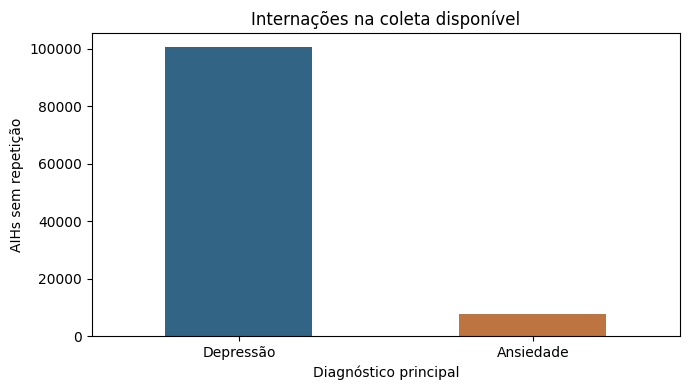

In [46]:
# Desenha a distribuição dos diagnósticos da base final.
# Gera diagnosticos.png e exibe o gráfico na saída.

grafico_diagnosticos(dados, PASTA_RESULTADOS)  # Gera, grava e mostra o gráfico de diagnósticos.

### Funções para agrupamento e associação

In [47]:
# Define a função preparar_matriz: transforma permanência e valor e coloca os atributos na mesma escala.
# Quando chamada, retorna numpy.ndarray: Idade e logaritmos padronizados.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def preparar_matriz(dados):  # Define os atributos numéricos usados pelo K-Means.
    """Transforma permanência e valor e coloca os atributos na mesma escala.

    Args:
        dados: Base de internações válida.

    Returns:
        numpy.ndarray: Idade e logaritmos padronizados.
    """
    matriz = dados[['idade_anos', 'dias', 'valor']].copy()  # Copia idade, permanência e pagamento, nessa ordem.
    matriz[['dias', 'valor']] = np.log1p(matriz[['dias', 'valor']])  # Calcula ln(1+x) para dias e pagamento, preservando os zeros.
    exigir(np.isfinite(matriz.to_numpy(dtype=float)).all(), 'Há valores não finitos na matriz.')  # Rejeita números infinitos ou ausentes na matriz convertida para float.
    return StandardScaler().fit_transform(matriz.astype(float))  # Padroniza as três colunas e devolve a matriz numérica.

In [48]:
# Define a função ajustar_modelo: ajusta K-Means com dez inicializações e semente fixa.
# Quando chamada, retorna sklearn.cluster.KMeans: Modelo ajustado.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def ajustar_modelo(matriz, quantidade, semente=42):  # Define um ajuste reproduzível do K-Means.
    """Ajusta K-Means com dez inicializações e semente fixa.

    Args:
        matriz: Atributos padronizados.
        quantidade: Número de grupos.
        semente: Semente para reprodução do ajuste.

    Returns:
        sklearn.cluster.KMeans: Modelo ajustado.
    """
    return KMeans(n_clusters=quantidade, n_init=10, random_state=semente).fit(matriz)  # Ajusta o k recebido com dez inicializações e a semente informada.

In [49]:
# Define a função avaliar_modelo: mede a separação na mesma amostra para cada número de grupos.
# Quando chamada, retorna dict: Inércia, silhouette amostral e Davies-Bouldin completo.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def avaliar_modelo(matriz, quantidade, amostra):  # Define a medição de um ajuste para determinado número de grupos.
    """Mede a separação na mesma amostra para cada número de grupos.

    Args:
        matriz: Atributos padronizados completos.
        quantidade: Número de grupos avaliado.
        amostra: Índices fixos para a silhouette.

    Returns:
        dict: Inércia, silhouette amostral e Davies-Bouldin completo.
    """
    modelo = ajustar_modelo(matriz, quantidade)  # Ajusta o K-Means na matriz completa.
    try:  # Tenta medir a separação dos grupos na amostra fixa.
        silhueta = silhouette_score(matriz[amostra], modelo.labels_[amostra])  # Calcula a silhouette somente para os índices da amostra recebida.
    except ValueError:  # Trata uma combinação de amostra e rótulos que não permita a métrica.
        silhueta = np.nan  # Marca a silhouette como ausente, sem inventar uma pontuação.
    return dict(k=quantidade, inercia=modelo.inertia_, silhouette=silhueta,  # Retorna k, soma das distâncias quadráticas e silhouette amostral.
                davies_bouldin=davies_bouldin_score(matriz, modelo.labels_))  # Acrescenta Davies-Bouldin, calculado com todos os registros.

In [50]:
# Define a função comparar_grupos: avalia k entre dois e dez respeitando o tamanho e a diversidade da base.
# Quando chamada, retorna pandas.DataFrame: Métricas dos números de grupos possíveis.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def comparar_grupos(matriz):  # Define a comparação dos números de grupos possíveis para a base.
    """Avalia k entre dois e dez respeitando o tamanho e a diversidade da base.

    Args:
        matriz: Atributos padronizados.

    Returns:
        pandas.DataFrame: Métricas dos números de grupos possíveis.
    """
    limite = min(10, len(matriz) - 1, len(np.unique(matriz, axis=0)) - 1)  # Limita k a dez e considera o tamanho e a diversidade da matriz.
    exigir(limite >= 2, 'A base não tem diversidade suficiente para agrupamento.')  # Exige observações distintas suficientes para testar pelo menos dois grupos.
    amostra = np.random.default_rng(42).choice(len(matriz), min(10000, len(matriz)), replace=False)  # Sorteia até 10.000 índices sem reposição, reduzindo o ruído amostral na escolha de k.
    metricas = pd.DataFrame([avaliar_modelo(matriz, k, amostra) for k in range(2, limite + 1)])  # Avalia todos os valores de k entre dois e o limite permitido.
    exigir(metricas.silhouette.notna().any(), 'Nenhum agrupamento pôde ser avaliado.')  # Exige pelo menos uma silhouette válida antes de selecionar um ajuste.
    return metricas  # Devolve a tabela comparativa de métricas por k.


In [51]:
# Define a função medir_estabilidade: compara todos os pares de cinco ajustes com sementes diferentes.
# Quando chamada, retorna pandas.DataFrame: ARI para os dez pares de sementes.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def medir_estabilidade(matriz, quantidade):  # Define a comparação dos agrupamentos obtidos com sementes distintas.
    """Compara todos os pares de cinco ajustes com sementes diferentes.

    Args:
        matriz: Atributos padronizados.
        quantidade: Número de grupos escolhido.

    Returns:
        pandas.DataFrame: ARI para os dez pares de sementes.
    """
    rotulos = {s: ajustar_modelo(matriz, quantidade, s).labels_ for s in [10, 21, 42, 73, 99]}  # Ajusta o mesmo k com cinco sementes e guarda os rótulos de cada ajuste.
    pares = [dict(semente_a=a, semente_b=b, ari=adjusted_rand_score(rotulos[a], rotulos[b]))  # Calcula o ARI para um par de ajustes por vez.
             for a, b in combinations(rotulos, 2)]  # Percorre todos os dez pares possíveis entre as cinco sementes.
    return pd.DataFrame(pares)  # Devolve a tabela de sementes e concordância entre rótulos.

In [52]:
# Define a função agrupar: seleciona o k com maior silhouette e adiciona os rótulos à base.
# Quando chamada, retorna tuple: Base rotulada, métricas e estabilidade dos ajustes.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def agrupar(dados):  # Define a execução principal do agrupamento.
    """Seleciona o k com maior silhouette e adiciona os rótulos à base.

    Args:
        dados: Internações válidas.

    Returns:
        tuple: Base rotulada, métricas e estabilidade dos ajustes.
    """
    matriz = preparar_matriz(dados)  # Transforma e padroniza os três atributos numéricos.
    metricas = comparar_grupos(matriz)  # Calcula as métricas para os valores de k permitidos.
    melhor = int(metricas.sort_values(['silhouette', 'davies_bouldin'], ascending=[False, True]).iloc[0].k)  # Seleciona a maior silhouette; usa menor Davies-Bouldin no desempate.
    resultado = dados.assign(agrupamento=ajustar_modelo(matriz, melhor).labels_)  # Ajusta o k escolhido e acrescenta o rótulo de grupo a cada registro.
    return resultado, metricas, medir_estabilidade(matriz, melhor)  # Devolve a base rotulada, as métricas e a estabilidade entre sementes.

In [53]:
# Define a função resumir_perfis: resume características observadas de cada grupo encontrado.
# Quando chamada, retorna pandas.DataFrame: Tamanho, medianas e composição dos grupos.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def resumir_perfis(dados):  # Define as características descritivas de cada agrupamento.
    """Resume características observadas de cada grupo encontrado.

    Args:
        dados: Internações com rótulos do K-Means.

    Returns:
        pandas.DataFrame: Tamanho, medianas e composição dos grupos.
    """
    return dados.groupby('agrupamento').agg(n=('grupo', 'size'), idade_mediana=('idade_anos', 'median'),  # Agrupa pelos rótulos e calcula a quantidade e a idade mediana.
        dias_mediana=('dias', 'median'), valor_mediano=('valor', 'median'),  # Calcula as medianas de permanência e pagamento por grupo.
        pagamentos_zero=('valor', lambda s: int(s.eq(0).sum())),  # Conta quantos registros de cada grupo têm pagamento registrado igual a zero.
        feminino_pct=('sexo', lambda s: s.eq('Feminino').mean() * 100),  # Calcula a porcentagem de registros do sexo feminino no grupo.
        depressao_pct=('grupo', lambda s: s.eq('Depressão').mean() * 100),  # Calcula a porcentagem de diagnósticos de depressão no grupo.
        obitos=('obito', 'sum'), obitos_informados=('obito', 'count')).reset_index()  # Registra óbitos e seu denominador informado; devolve uma linha por grupo.


In [54]:
# Define a função categorizar_tercis: cria até três intervalos por quantis sem limites arredondados.
# Quando chamada, retorna tuple: Categoria por registro e limites exatos exportáveis.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def categorizar_tercis(serie, nome):  # Define até três faixas numéricas a partir dos quantis.
    """Cria até três intervalos por quantis sem limites arredondados.

    Args:
        serie: Campo numérico completo.
        nome: Nome do campo para identificar os itens.

    Returns:
        tuple: Categoria por registro e limites exatos exportáveis.
    """
    cortes = np.unique(np.r_[-np.inf, serie.quantile([1 / 3, 2 / 3]).to_numpy(), np.inf])  # Calcula cortes de 1/3 e 2/3, com extremos infinitos e sem cortes repetidos.
    rotulos = [f'{nome}_faixa_{i + 1}' for i in range(len(cortes) - 1)]  # Cria um nome sequencial para cada intervalo realmente existente.
    categoria = pd.cut(serie, cortes, labels=rotulos, include_lowest=True)  # Atribui cada valor a um intervalo fechado à direita.
    limites = pd.DataFrame(dict(atributo=nome, categoria=rotulos, inferior=cortes[:-1], superior=cortes[1:]))  # Monta a tabela com os limites exatos de cada faixa.
    return categoria.astype('string'), limites  # Devolve as categorias textuais e a tabela de limites.

In [55]:
# Define a função criar_itens: monta categorias para o Apriori sem usar rótulos de agrupamento.
# Quando chamada, retorna tuple: Itens de cada internação e tabela dos cortes numéricos.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def criar_itens(dados):  # Define as características que vão compor cada transação do Apriori.
    """Monta categorias para o Apriori sem usar rótulos de agrupamento.

    Args:
        dados: Internações preparadas.

    Returns:
        tuple: Itens de cada internação e tabela dos cortes numéricos.
    """
    itens = dados[['grupo', 'sexo', 'faixa_etaria', 'regiao', 'carater']].astype('string').copy()  # Copia as cinco categorias descritivas, mantendo ausências como ausências.
    itens['permanencia'], limites_dias = categorizar_tercis(dados.dias, 'permanencia')  # Cria as faixas de permanência e guarda seus limites.
    itens['valor'], limites_valor = categorizar_tercis(dados.valor, 'valor')  # Cria as faixas de pagamento e guarda seus limites.
    itens['obito'] = dados.obito.eq(1).map({True: 'Sim', False: pd.NA}).astype('string')  # Cria o item de óbito apenas para código 1; não cria item de sobrevivência.
    return itens, pd.concat([limites_dias, limites_valor], ignore_index=True)  # Devolve os itens por internação e os limites das duas variáveis.

In [56]:
# Define a função gerar_regras: calcula regras ou devolve uma tabela vazia com esquema conhecido.
# Quando chamada, retorna pandas.DataFrame: Regras com suporte, confiança, lift e contagem conjunta.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def gerar_regras(frequentes, quantidade):  # Define as regras e seus limiares de confiança e lift.
    """Calcula regras ou devolve uma tabela vazia com esquema conhecido.

    Args:
        frequentes: Itemsets produzidos pelo Apriori.
        quantidade: Número total de transações.

    Returns:
        pandas.DataFrame: Regras com suporte, confiança, lift e contagem conjunta.
    """
    try:  # Tenta verificar se existe algum conjunto com pelo menos dois itens.
        exigir(frequentes.itemsets.map(len).ge(2).any(), 'Não há itemsets combinados.')  # Exige uma combinação que possa ser separada em dois lados de uma regra.
    except ValueError:  # Trata a ausência de combinações elegíveis.
        return pd.DataFrame(columns=['antecedents', 'consequents', 'support', 'confidence', 'lift', 'n_conjunto'])  # Devolve uma tabela vazia com as colunas esperadas quando não há combinações.
    regras = association_rules(frequentes, num_itemsets=quantidade, metric='confidence', min_threshold=0.60)  # Gera regras com confiança de pelo menos 60%, usando o total de transações.
    regras = regras.loc[regras.lift.ge(1.10)].copy()  # Mantém somente regras com lift igual ou maior que 1,10.
    regras['n_conjunto'] = np.rint(regras.support * quantidade).astype(int)  # Converte o suporte em quantidade conjunta de internações, com arredondamento.
    return regras  # Devolve as regras que atenderam aos limiares.

In [57]:
# Define a função regra_nao_redundante: identifica regras que não combinam diretamente valor e permanência.
# Quando chamada, retorna bool: Indica se a regra permanece na seleção para interpretação.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def regra_nao_redundante(regra):  # Define o filtro de interpretação das regras calculadas.
    """Identifica regras que não combinam diretamente valor e permanência.

    Args:
        regra: Linha com antecedente e consequente.

    Returns:
        bool: Indica se a regra permanece na seleção para interpretação.
    """
    itens = ' '.join(regra.antecedents | regra.consequents)  # Reúne os nomes dos itens dos dois lados da regra.
    return not ('permanencia_' in itens and 'valor_' in itens)  # Exclui da seleção regras que combinam permanência e pagamento.

In [58]:
# Define a função associar: executa Apriori com parâmetros definidos antes da interpretação.
# Quando chamada, retorna tuple: Todas as regras, regras selecionadas e limites das faixas.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def associar(dados):  # Define a sequência do Apriori e da seleção de regras.
    """Executa Apriori com parâmetros definidos antes da interpretação.

    Args:
        dados: Base final de internações.

    Returns:
        tuple: Todas as regras, regras selecionadas e limites das faixas.
    """
    itens, limites = criar_itens(dados)  # Cria as categorias por internação e guarda os limites dos cortes.
    transacoes = pd.get_dummies(itens, prefix_sep='=', dtype=bool)  # Transforma cada categoria em uma coluna booleana de presença do item.
    frequentes = apriori(transacoes, min_support=0.05, use_colnames=True, max_len=3)  # Procura conjuntos de até três itens com suporte mínimo de 5%.
    regras = gerar_regras(frequentes, len(dados))  # Calcula as regras que atendem aos limiares de confiança e lift.
    mascara = pd.Series([regra_nao_redundante(r) for r in regras.itertuples()], index=regras.index, dtype=bool)  # Identifica as regras que passam no filtro de permanência e pagamento.
    selecionadas = regras.loc[mascara].sort_values(['lift', 'confidence', 'support'], ascending=False)  # Ordena a seleção por lift, confiança e suporte, do maior para o menor.
    return regras, selecionadas, limites  # Devolve as regras completas, a seleção e os limites das faixas.

In [59]:
# Define a função serializar_regras: converte conjuntos de itens em texto com ordenação reproduzível.
# Quando chamada, retorna pandas.DataFrame: Regras prontas para CSV e apresentação.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def serializar_regras(regras):  # Define a conversão dos conjuntos de itens em textos exportáveis.
    """Converte conjuntos de itens em texto com ordenação reproduzível.

    Args:
        regras: Regras calculadas pelo Apriori.

    Returns:
        pandas.DataFrame: Regras prontas para CSV e apresentação.
    """
    resultado = regras.copy()  # Copia a tabela para não alterar os conjuntos usados nos cálculos.
    for coluna in ['antecedents', 'consequents']:  # Percorre as colunas do antecedente e do consequente.
        resultado[coluna] = resultado[coluna].map(lambda itens: ' e '.join(sorted(itens)))  # Ordena os nomes e junta os itens com a palavra e.
    return resultado  # Devolve a tabela pronta para leitura e gravação em CSV.

In [60]:
# Define a função avaliar_sem_pagamento: compara o agrupamento com um ajuste que não usa pagamento.
# Quando chamada, retorna float: ARI entre os ajustes com o mesmo número de grupos.
# Esta célula disponibiliza a função no kernel; seu corpo só roda na chamada.

def avaliar_sem_pagamento(dados):  # Define a comparação de sensibilidade à retirada do pagamento.
    """Compara o agrupamento com um ajuste que não usa pagamento.

    Args:
        dados: Base com os rótulos do modelo de três atributos.

    Returns:
        float: ARI entre os ajustes com o mesmo número de grupos.
    """
    matriz = dados[['idade_anos', 'dias']].astype(float).copy()  # Copia apenas idade e permanência como números de ponto flutuante.
    matriz['dias'] = np.log1p(matriz.dias)  # Aplica ln(1+x) à permanência, incluindo os valores iguais a zero.
    matriz = StandardScaler().fit_transform(matriz)  # Padroniza as duas colunas, sem usar pagamento.
    rotulos = ajustar_modelo(matriz, dados.agrupamento.nunique()).labels_  # Ajusta o mesmo número de grupos do modelo principal.
    return float(adjusted_rand_score(dados.agrupamento, rotulos))  # Retorna o ARI entre os rótulos do modelo principal e desse ajuste.

## 5 Agrupamento dos perfis de internação

Usamos idade, logaritmo de 1 mais a permanência e logaritmo de 1 mais o pagamento. O log reduz a influência de valores extremos sem excluí-los. A padronização impede que a unidade de uma variável domine a distância. Como há uma distância elevada entre pagamento igual a zero e o menor valor positivo após a transformação logarítmica, verificamos explicitamente quantos registros com pagamento zero ficam em cada grupo.

O K-Means é exploratório: os grupos não são tipos clínicos, diagnósticos nem níveis comprovados de gravidade. Testamos k de 2 a 10 quando há observações distintas suficientes. A silhouette usa a mesma amostra fixa de até 10.000 registros em todos os ajustes para reduzir o ruído amostral na seleção; inércia e Davies-Bouldin usam a base completa. Escolhemos a maior silhouette e usamos Davies-Bouldin para desempatar. O gráfico da inércia permite revisar essa decisão. Os rótulos são arbitrários.

A estabilidade compara dez pares de ajustes de cinco sementes. ARI alto indica repetibilidade do algoritmo, não comprovação clínica. Também comparamos os rótulos com um ajuste sem pagamento, mantendo o mesmo k, para verificar quanto esse atributo altera a composição dos grupos. Essa comparação não escolhe um segundo modelo final. A correlação entre permanência e pagamento é exportada para explicitar a possível redundância dessas variáveis.


In [61]:
# Executa o K-Means, escolhe k e resume os grupos.
# Gera dados rotulados, metricas, estabilidade, perfis e o CSV das métricas.

with threadpool_limits(limits=2):  # Limita a duas as threads das bibliotecas numéricas durante o ajuste.
    dados, metricas, estabilidade = agrupar(dados)  # Executa os agrupamentos e recebe a base rotulada, métricas e estabilidade.
perfis = resumir_perfis(dados)  # Resume o tamanho e as características de cada grupo escolhido.
salvar_tabela(metricas, 'metricas_agrupamento', PASTA_RESULTADOS)  # Grava as métricas calculadas para cada valor de k.

In [62]:
# Guarda e mostra os perfis e a estabilidade entre sementes.
# Grava dois CSVs e exibe as três tabelas de avaliação.

salvar_tabela(estabilidade, 'estabilidade_ari', PASTA_RESULTADOS)  # Grava a concordância entre todos os pares de sementes.
salvar_tabela(perfis, 'perfis_agrupamento', PASTA_RESULTADOS)  # Grava as características descritivas dos grupos encontrados.
display(metricas, perfis, estabilidade)  # Mostra as métricas, os perfis e a estabilidade calculada.

,k,inercia,silhouette,davies_bouldin
0,2,211250.089041,0.331602,1.201802
1,3,153133.069207,0.371500,1.061271
2,4,118060.894257,0.364560,0.924612
3,5,95207.720858,0.355384,0.901510
4,6,80600.732585,0.366923,0.939547
5,7,72049.780527,0.332204,0.970866
6,8,65052.299807,0.334415,0.955948
7,9,58759.273538,0.328899,0.916497
8,10,52865.221717,0.328783,0.896243


,agrupamento,n,idade_mediana,dias_mediana,valor_mediano,pagamentos_zero,feminino_pct,depressao_pct,obitos,obitos_informados
0,0,50379,30.0,2.0,114.0,0.0,66.279601,89.620675,93,50379
1,1,36828,44.0,18.0,951.6,0.0,62.938525,96.225698,116,36828
2,2,20944,35.0,5.0,0.0,20944.0,65.928189,94.843392,37,20944


,semente_a,semente_b,ari
0,10,21,0.995626
1,10,42,0.995786
2,10,73,0.997987
3,10,99,0.997412
4,21,42,0.996966
5,21,73,0.997636
6,21,99,0.997764
7,42,73,0.997030
8,42,99,0.996583
9,73,99,0.999361


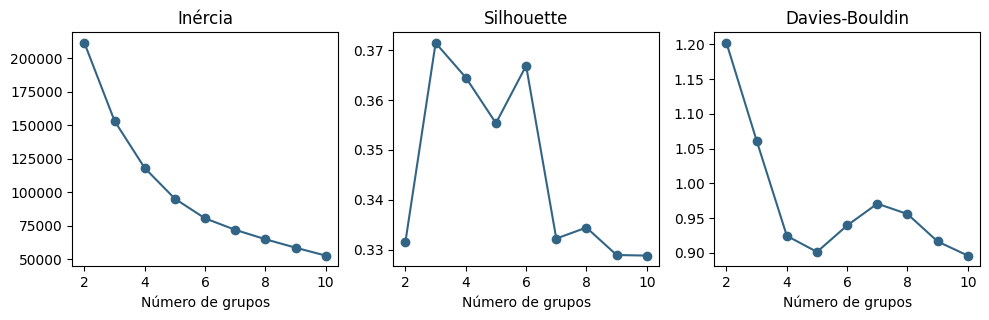

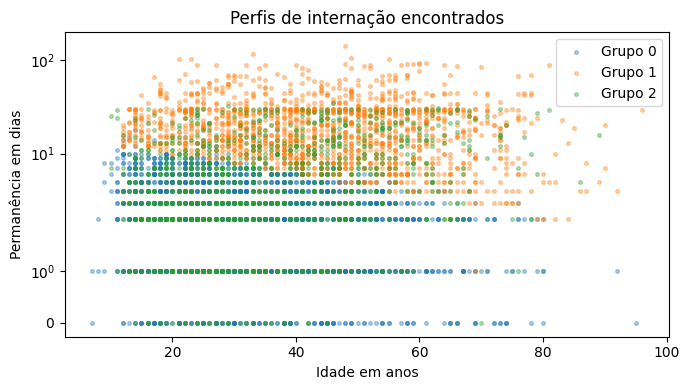

In [63]:
# Apresenta os ajustes testados e a distribuição dos grupos.
# Grava e exibe metricas_agrupamento.png e perfis_agrupamento.png.

grafico_metricas(metricas, PASTA_RESULTADOS)  # Gera e grava os três gráficos de comparação dos valores de k.
grafico_perfis(dados, PASTA_RESULTADOS)  # Gera e grava o gráfico de idade e permanência por grupo.

## 6 Regras de associação

Cada AIH é uma transação. Os itens representam diagnóstico, sexo, faixa etária, região de atendimento, caráter, faixas de permanência e pagamento e óbito informado como positivo. As faixas numéricas usam quantis; seus limites exatos ficam no CSV. Empates podem produzir tamanhos diferentes. Ausência não vira categoria de sobrevivência.

O Apriori usa suporte mínimo de 5%, até três itens, confiança mínima de 60% e lift mínimo de 1,10. Os parâmetros foram mantidos do planejamento. Casos raros podem não aparecer com suporte de 5%. As regras que combinam pagamento e permanência são preservadas no arquivo completo, mas retiradas da seleção interpretada para reduzir associações ligadas à duração e remuneração.

Suporte é a fração de todas as internações que contém os dois lados da regra. Confiança é a fração das internações com o antecedente que também tem o consequente. Lift compara essa confiança à frequência do consequente. Nenhuma dessas medidas demonstra causa e efeito. O agrupamento não entra como item para evitar regras circulares.

In [64]:
# Calcula as associações e exporta suas versões completas e selecionadas.
# Gera regras, selecionadas, limites e os dois CSVs de regras.

regras, selecionadas, limites = associar(dados)  # Executa Apriori e recebe regras completas, seleção e limites das faixas.
salvar_tabela(serializar_regras(regras), 'regras_completas', PASTA_RESULTADOS)  # Grava todas as regras que atenderam aos limiares, com itens em texto.
salvar_tabela(serializar_regras(selecionadas), 'regras_selecionadas', PASTA_RESULTADOS)  # Grava apenas as regras mantidas para interpretação.

In [65]:
# Documenta os cortes numéricos e mostra as regras selecionadas.
# Grava limites_faixas.csv e exibe contagens e métricas das regras.

salvar_tabela(limites, 'limites_faixas', PASTA_RESULTADOS)  # Grava os limites numéricos exatos usados nas faixas.
print(f'Regras com os limiares definidos: {len(regras)}; após seleção: {len(selecionadas)}.')  # Mostra a quantidade de regras antes e depois do filtro de interpretação.
display(serializar_regras(selecionadas).head(15)[['antecedents', 'consequents', 'support', 'confidence', 'lift', 'n_conjunto']])  # Mostra até quinze regras selecionadas, com métricas e contagem conjunta.

Regras com os limiares definidos: 45; após seleção: 9.


,antecedents,consequents,support,confidence,lift,n_conjunto
182,carater=Eletivo e grupo=Depressão,permanencia=permanencia_faixa_3,0.069070,0.645301,2.039806,7470
49,carater=Eletivo,permanencia=permanencia_faixa_3,0.072316,0.638449,2.018147,7821
183,carater=Eletivo,grupo=Depressão e permanencia=permanencia_faixa_3,0.069070,0.609796,1.996610,7470
216,faixa_etaria=12 a 17,carater=Urgência e sexo=Feminino,0.070392,0.742080,1.281831,7613
215,carater=Urgência e faixa_etaria=12 a 17,sexo=Feminino,0.070392,0.783392,1.203850,7613
60,faixa_etaria=12 a 17 e grupo=Depressão,sexo=Feminino,0.068266,0.782015,1.201734,7383
22,faixa_etaria=12 a 17,sexo=Feminino,0.073961,0.779706,1.198186,7999
61,faixa_etaria=12 a 17,grupo=Depressão e sexo=Feminino,0.068266,0.719661,1.194274,7383
240,regiao=Centro-Oeste,carater=Urgência e sexo=Feminino,0.057392,0.678287,1.171637,6207


## 7 Exportação e limites da interpretação

Os resultados são salvos em CSV com separador `;`, decimal `,` e codificação UTF-8. A base para análise é exportada sem o número da AIH e sem datas individuais, que não são necessários para ler os resultados. O cache de trabalho conserva os campos mínimos usados na deduplicação e validação e não deve ser publicado no GitHub.

O estudo descreve internações financiadas pelo SUS com os quatro prefixos como diagnóstico principal. Não mede prevalência de depressão e ansiedade, atendimentos ambulatoriais, pessoas únicas ou o total privado. A coleta parcial impede generalizações sobre totais nacionais e evolução anual. Os resultados não sustentam conclusão causal sobre a pandemia.

In [66]:
# Reúne as métricas finais e verifica a sensibilidade ao pagamento.
# Gera o dicionário execucao, incluindo o ARI do ajuste sem pagamento.

execucao = resumo_execucao(dados, bruto, cobertura, metricas, estabilidade)  # Reúne contagens, decisão de k, métricas e versões dos pacotes.
execucao['cobertura'] = 'parcial' if execucao['obtidos'] < execucao['esperados'] else 'completa'  # Identifica a cobertura como parcial quando obtidos é menor que esperados.
with threadpool_limits(limits=2):  # Limita as threads durante o ajuste usado na comparação de sensibilidade.
    execucao['ari_sem_pagamento'] = avaliar_sem_pagamento(dados)  # Compara o modelo principal com o ajuste sem pagamento, mantendo o mesmo k.

In [67]:
# Acrescenta as contagens de continuações, pagamentos zero e regras ao registro.
# Atualiza os campos de contagem e auditoria no dicionário execucao.

execucao['amostra_silhouette'] = int(min(10000, len(dados)))  # Registra o tamanho da amostra fixa utilizada no cálculo da silhouette.
execucao['episodios_com_continuacao'] = int(dados.continuacoes.gt(0).sum())  # Conta quantas AIHs normais receberam ao menos uma continuação consolidada.
execucao['continuacoes_consolidadas'] = int(dados.continuacoes.sum())  # Registra o total de AIHs de continuação somadas às AIHs iniciais.
execucao['pagamentos_zero'] = int(dados.valor.eq(0).sum())  # Conta os registros cujo pagamento está informado como zero.
execucao['regras_completas'] = len(regras)  # Registra quantas regras passaram nos limiares originais.
execucao['regras_selecionadas'] = len(selecionadas)  # Registra quantas regras permaneceram na seleção para interpretação.


In [68]:
# Exporta o registro de execução e os campos finais da base.
# Grava execucao.json e base_analise.parquet, sem N_AIH nem datas individuais.

salvar_json(execucao, PASTA_RESULTADOS / 'execucao.json')  # Salva o registro completo de execução em JSON.
campos = ['grupo', 'sexo', 'idade_anos', 'faixa_etaria', 'uf', 'regiao', 'carater', 'dias', 'valor', 'obito', 'continuacoes', 'ano_processamento', 'mes_processamento', 'agrupamento']  # Escolhe os campos exportados, sem N_AIH nem datas individuais.
dados[campos].to_parquet(PASTA_RESULTADOS / 'base_analise.parquet', index=False)  # Grava a base final em Parquet, sem transformar o índice em coluna.


In [69]:
# Mostra o registro final e o local dos arquivos gerados.
# Exibe a tabela de execução e informa a pasta de resultados.

display(pd.Series(execucao).to_frame('resultado'))  # Mostra o registro da execução como uma tabela.
print('Tabelas, gráficos e dados para análise disponíveis em:', PASTA_RESULTADOS)  # Informa a pasta em que as tabelas, os gráficos e a base foram salvos.

,resultado
data_utc,2026-11-26T21:57:56.492577+00:00
selecionados,118173
analisados,108151
esperados,972
obtidos,764
k,3
silhouette,0.3715
davies_bouldin,1.061271
ari_medio,0.997215
ari_minimo,0.995626


Tabelas, gráficos e dados para análise disponíveis em: c:\Users\T-Gamer\Desktop\projeto mineração de dados\projeto_mineracao\internacoes_sus\internacoes_sus\resultados


## Referências e documentação

- DATASUS. SIH/SUS: https://datasus.saude.gov.br/transferencia-de-arquivos/
- PySUS 2.11.7: https://pysus.readthedocs.io/en/stable/quickstart.html
- Carvalho et al. (2023): https://doi.org/10.1590/S2237-96222023000100016
- Papini et al. (2025): https://doi.org/10.47385/tudoeciencia.2352.2025
- Agrawal e Srikant (1994): https://www.vldb.org/conf/1994/P487.PDF
- Pedregosa et al. (2011): https://www.jmlr.org/papers/v12/pedregosa11a.html

O trabalho escrito acompanha os resultados desta execução. Ao atualizar o catálogo ou o recorte, execute todas as células novamente e atualize os números do relatório.